# V2V Dataset Exploratory Data Analysis

This notebook performs comprehensive EDA on the V2V communication dataset for anomaly detection.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
from scipy import stats
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
%matplotlib inline

## 1. Data Loading and Basic Information

In [2]:
data_path = Path('../data')
df = pd.read_csv(data_path / 'v2v_dataset_20251017_124247.csv')

with open(data_path / 'metadata_20251017_124247.json', 'r') as f:
    metadata = json.load(f)

print("Dataset Metadata:")
for key, value in metadata.items():
    print(f"  {key}: {value}")

Dataset Metadata:
  session_id: 20251017_124247
  total_records: 4048814
  unique_vehicles: 3999
  duration_seconds: 3599.9
  sampling_rate_hz: 10
  sensor_types: ['GPS', 'IMU', 'Compass']
  gps_noise_std_meters: 2.0
  imu_accel_noise_std: 0.1
  imu_gyro_noise_std: 0.01


In [3]:
print(f"\nDataset Shape: {df.shape}")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"\nColumn Types:\n{df.dtypes}")


Dataset Shape: (4048814, 23)
Memory Usage: 710.47 MB

Column Types:
frame           int64
timestamp     float64
vehicle_id      int64
latitude      float64
longitude     float64
altitude      float64
x             float64
y             float64
z             float64
roll          float64
pitch         float64
yaw           float64
velocity_x    float64
velocity_y    float64
velocity_z    float64
speed         float64
accel_x       float64
accel_y       float64
accel_z       float64
gyro_x        float64
gyro_y        float64
gyro_z        float64
compass       float64
dtype: object


In [4]:
df.head(10)

,frame,timestamp,vehicle_id,latitude,longitude,altitude,x,y,z,roll,...,velocity_y,velocity_z,speed,accel_x,accel_y,accel_z,gyro_x,gyro_y,gyro_z,compass
0,1,0.1,0,41.385096,2.180763,47.894325,613.612038,-1.6,0.3,0.166778,...,13.120379,0.0,13.120379,-4.022347e-17,-0.656899,-9.764047,-0.008922,0.001877,0.007566,1.552361
1,2,0.2,0,41.385068,2.180771,50.091346,614.925992,-1.6,0.3,0.593813,...,13.139539,0.0,13.139539,6.346076e-18,0.103639,-9.794538,-0.004724,-0.004240,0.001631,1.577897
2,3,0.3,0,41.385089,2.180796,48.719035,616.237970,-1.6,0.3,0.576710,...,13.119778,0.0,13.119778,-1.157576e-17,-0.189047,-9.768138,0.001281,0.001637,-0.007006,1.572252
3,4,0.4,0,41.385106,2.180812,49.770578,617.552651,-1.6,0.3,-0.375111,...,13.146818,0.0,13.146818,7.859978e-18,0.128363,-9.751753,-0.009289,0.007527,0.013644,1.562107
4,5,0.5,0,41.385075,2.180815,51.186096,618.869349,-1.6,0.3,-0.423322,...,13.166981,0.0,13.166981,9.373114e-18,0.153075,-9.883128,0.004428,-0.002069,0.000529,1.554022
5,6,0.6,0,41.385093,2.180830,50.147199,620.175455,-1.6,0.3,0.674095,...,13.061053,0.0,13.061053,-6.771468e-17,-1.105865,-9.754616,-0.006910,-0.000461,-0.004701,1.580434
6,7,0.7,0,41.385061,2.180873,50.491608,621.481093,-1.6,0.3,0.671949,...,13.056380,0.0,13.056380,2.118045e-18,0.034590,-9.855638,-0.006061,0.002651,-0.001349,1.568378
7,8,0.8,0,41.385070,2.180861,51.042340,622.787915,-1.6,0.3,-0.523432,...,13.068217,0.0,13.068217,1.313189e-17,0.214460,-9.778943,0.000524,0.002334,-0.005828,1.572924
8,9,0.9,0,41.385084,2.180884,50.676069,624.101484,-1.6,0.3,-0.214526,...,13.135691,0.0,13.135691,3.776525e-17,0.616753,-9.871616,-0.003085,-0.003354,-0.004619,1.561203
9,10,1.0,0,41.385106,2.180921,49.528040,625.414200,-1.6,0.3,0.165018,...,13.127164,0.0,13.127164,-2.268394e-18,-0.037046,-9.798511,0.005233,-0.001540,0.008481,1.554669


## 2. Data Quality Assessment

In [5]:
print("Missing Values:")
missing = df.isnull().sum()
if missing.sum() > 0:
    print(missing[missing > 0])
else:
    print("No missing values found")

Missing Values:
No missing values found


In [6]:
print("Duplicate Rows:")
duplicates = df.duplicated().sum()
print(f"Total duplicates: {duplicates}")
if duplicates > 0:
    print(f"Percentage: {duplicates / len(df) * 100:.2f}%")

Duplicate Rows:
Total duplicates: 0


In [7]:
print("\nBasic Statistics:")
df.describe()


Basic Statistics:


,frame,timestamp,vehicle_id,latitude,longitude,altitude,x,y,z,roll,...,velocity_y,velocity_z,speed,accel_x,accel_y,accel_z,gyro_x,gyro_y,gyro_z,compass
count,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,...,4.048814e+06,4048814.0,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06,4.048814e+06
mean,1.854575e+04,1.854575e+03,1.993272e+03,4.138871e+01,2.178191e+00,4.999987e+01,3.989903e+02,4.011883e+02,3.000000e-01,2.274395e-04,...,2.381682e-02,0.0,9.501650e+00,1.080521e-03,4.368526e-04,-9.810007e+00,1.286811e-06,1.499129e-06,-1.179823e-02,2.496437e+00
std,1.024749e+04,1.024749e+03,1.136625e+03,2.178606e-03,2.812293e-03,9.999403e-01,2.342072e+02,2.418162e+02,1.665335e-16,4.999366e-01,...,7.661163e+00,0.0,5.428776e+00,8.949086e-01,1.082902e+00,5.000194e-02,4.999977e-03,4.999764e-03,2.274848e-01,1.769318e+00
min,1.000000e+00,1.000000e-01,0.000000e+00,4.138501e+01,2.173292e+00,4.444175e+01,-1.600000e+00,-1.600000e+00,3.000000e-01,-2.728618e+00,...,-1.909207e+01,0.0,0.000000e+00,-5.558495e+00,-8.889631e+00,-1.007577e+01,-2.429175e-02,-2.647540e-02,-3.171454e+00,-4.718907e-02
25%,9.695000e+03,9.695000e+02,1.011000e+03,4.138691e+01,2.175818e+00,4.932564e+01,2.016000e+02,2.016000e+02,3.000000e-01,-3.370024e-01,...,0.000000e+00,0.0,5.415910e+00,-3.998106e-16,-6.533596e-02,-9.843729e+00,-3.372138e-03,-3.371125e-03,-7.455269e-03,1.558853e+00
50%,1.862700e+04,1.862700e+03,2.010000e+03,4.138870e+01,2.178204e+00,5.000029e+01,4.008561e+02,4.016000e+02,3.000000e-01,1.149613e-04,...,0.000000e+00,0.0,1.197551e+01,-5.663053e-20,-0.000000e+00,-9.810003e+00,-3.412998e-07,8.792941e-07,-1.840179e-04,2.945721e+00
75%,2.763200e+04,2.763200e+03,2.987000e+03,4.139050e+01,2.180582e+00,5.067403e+01,5.984000e+02,5.984000e+02,3.000000e-01,3.371293e-01,...,5.685400e-03,0.0,1.369476e+01,6.630279e-16,6.408817e-02,-9.776297e+00,3.372044e-03,3.373670e-03,6.982966e-03,4.699278e+00
max,3.599900e+04,3.599900e+03,3.999000e+03,4.139240e+01,2.183102e+00,5.495955e+01,8.016000e+02,8.016000e+02,3.000000e-01,2.702623e+00,...,1.909183e+01,0.0,1.909207e+01,8.952915e+00,5.120948e+00,-9.564724e+00,2.607597e-02,2.705574e-02,2.189971e+00,6.305825e+00


## 3. Temporal Analysis

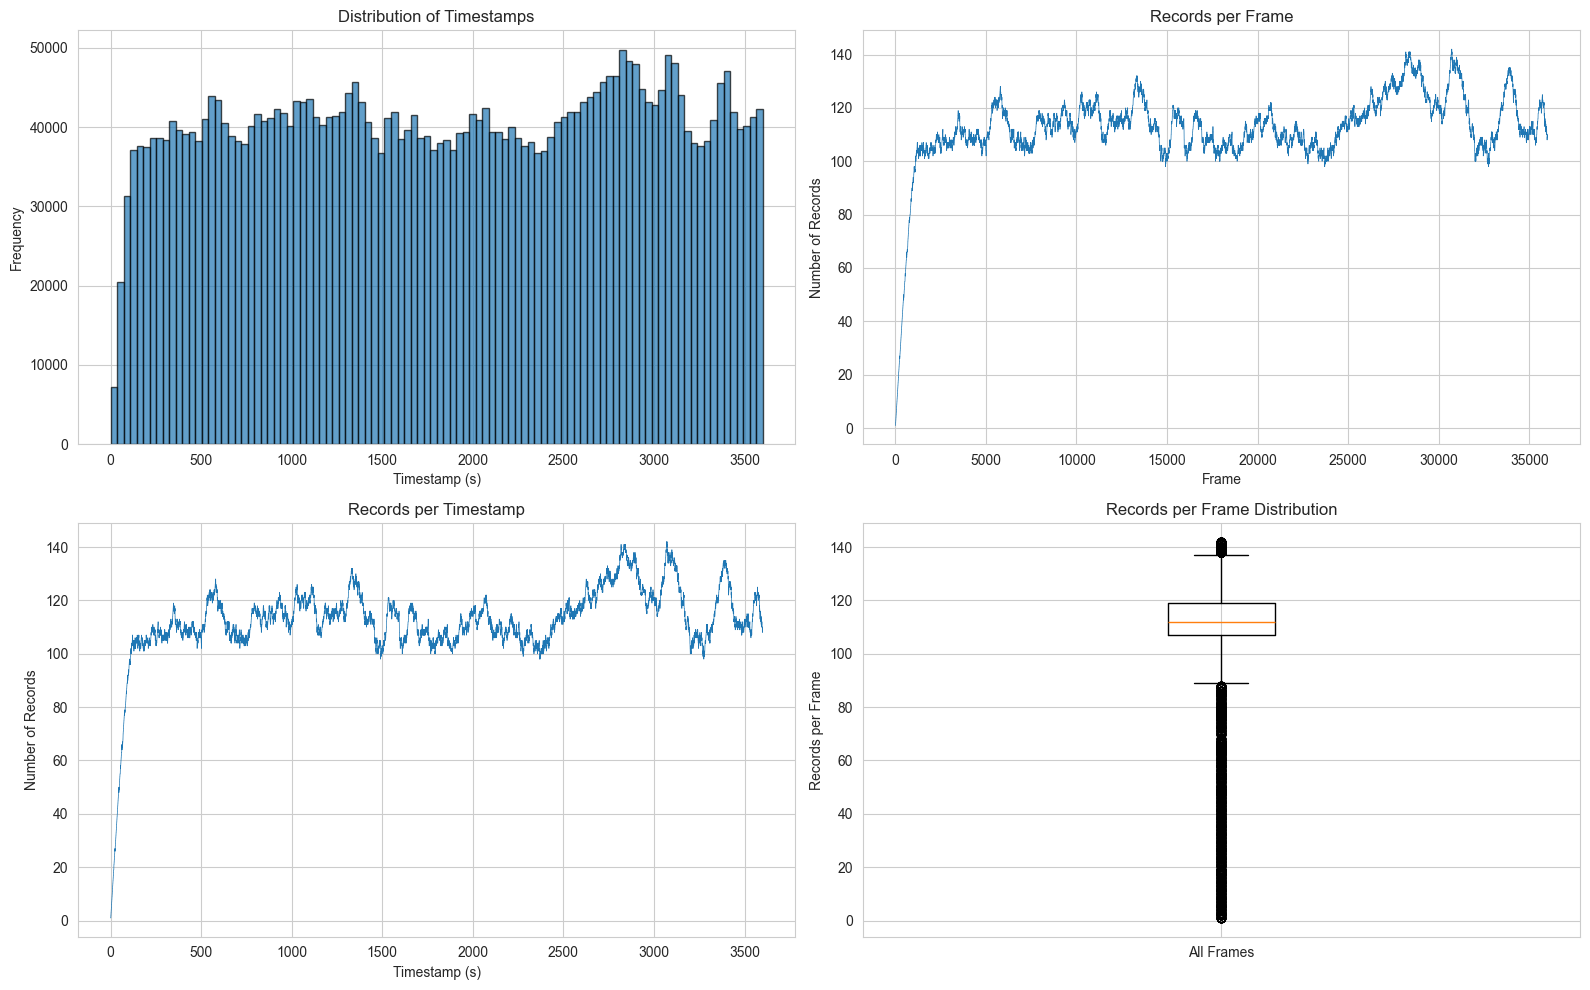


Temporal Statistics:
Time range: 0.10s - 3599.90s
Duration: 3599.80s
Frame range: 1 - 35999
Mean records per frame: 112.47
Std records per frame: 14.29


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].hist(df['timestamp'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Timestamp (s)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of Timestamps')

records_per_frame = df.groupby('frame').size()
axes[0, 1].plot(records_per_frame.index, records_per_frame.values, linewidth=0.5)
axes[0, 1].set_xlabel('Frame')
axes[0, 1].set_ylabel('Number of Records')
axes[0, 1].set_title('Records per Frame')

records_per_time = df.groupby('timestamp').size()
axes[1, 0].plot(records_per_time.index, records_per_time.values, linewidth=0.5)
axes[1, 0].set_xlabel('Timestamp (s)')
axes[1, 0].set_ylabel('Number of Records')
axes[1, 0].set_title('Records per Timestamp')

axes[1, 1].boxplot([records_per_frame.values])
axes[1, 1].set_ylabel('Records per Frame')
axes[1, 1].set_title('Records per Frame Distribution')
axes[1, 1].set_xticklabels(['All Frames'])

plt.tight_layout()
plt.show()

print("\nTemporal Statistics:")
print(f"Time range: {df['timestamp'].min():.2f}s - {df['timestamp'].max():.2f}s")
print(f"Duration: {df['timestamp'].max() - df['timestamp'].min():.2f}s")
print(f"Frame range: {df['frame'].min()} - {df['frame'].max()}")
print(f"Mean records per frame: {records_per_frame.mean():.2f}")
print(f"Std records per frame: {records_per_frame.std():.2f}")

## 4. Vehicle Analysis

Unique Vehicles: 3999

Records per Vehicle Statistics:
count    3999.000000
mean     1012.456614
std       444.332282
min         8.000000
25%       698.000000
50%       966.000000
75%      1270.500000
max      3585.000000
Name: count, dtype: float64


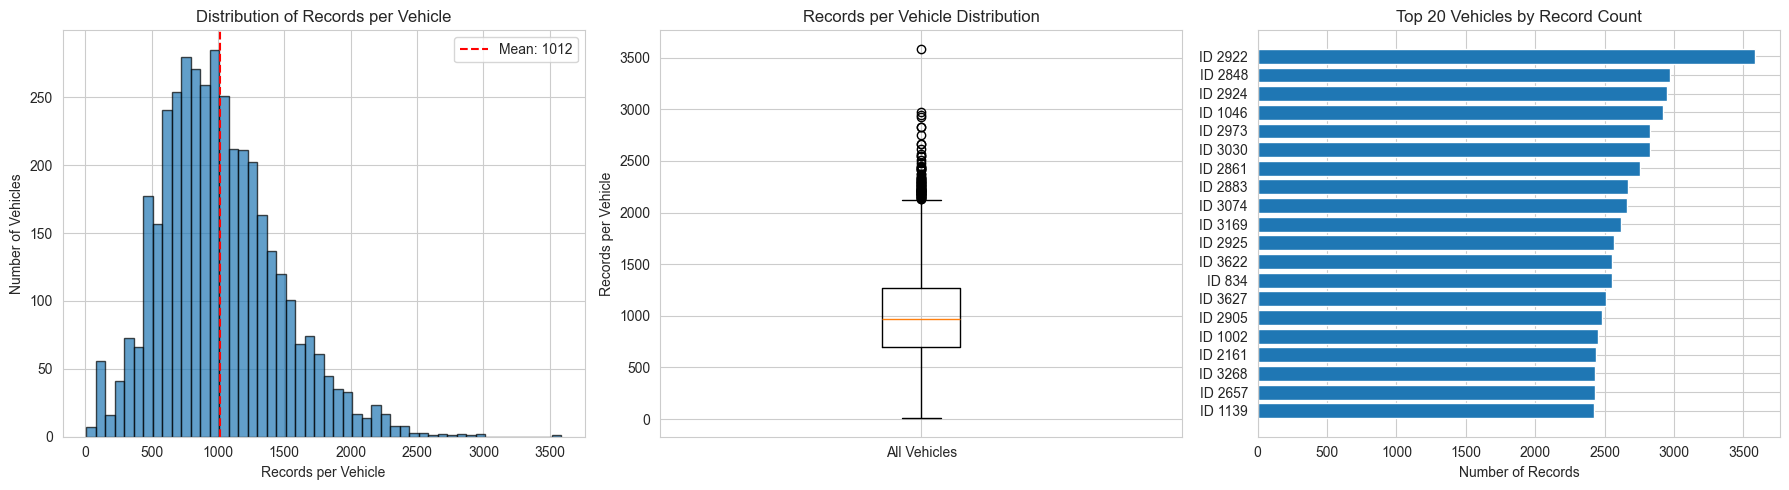

In [9]:
vehicle_counts = df['vehicle_id'].value_counts()

print(f"Unique Vehicles: {df['vehicle_id'].nunique()}")
print("\nRecords per Vehicle Statistics:")
print(vehicle_counts.describe())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(vehicle_counts.values, bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Records per Vehicle')
axes[0].set_ylabel('Number of Vehicles')
axes[0].set_title('Distribution of Records per Vehicle')
axes[0].axvline(vehicle_counts.mean(), color='red', linestyle='--', label=f'Mean: {vehicle_counts.mean():.0f}')
axes[0].legend()

axes[1].boxplot([vehicle_counts.values])
axes[1].set_ylabel('Records per Vehicle')
axes[1].set_title('Records per Vehicle Distribution')
axes[1].set_xticklabels(['All Vehicles'])

top_20 = vehicle_counts.head(20)
axes[2].barh(range(len(top_20)), top_20.values)
axes[2].set_yticks(range(len(top_20)))
axes[2].set_yticklabels([f"ID {idx}" for idx in top_20.index])
axes[2].set_xlabel('Number of Records')
axes[2].set_title('Top 20 Vehicles by Record Count')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

## 5. Spatial Analysis (GPS Data)

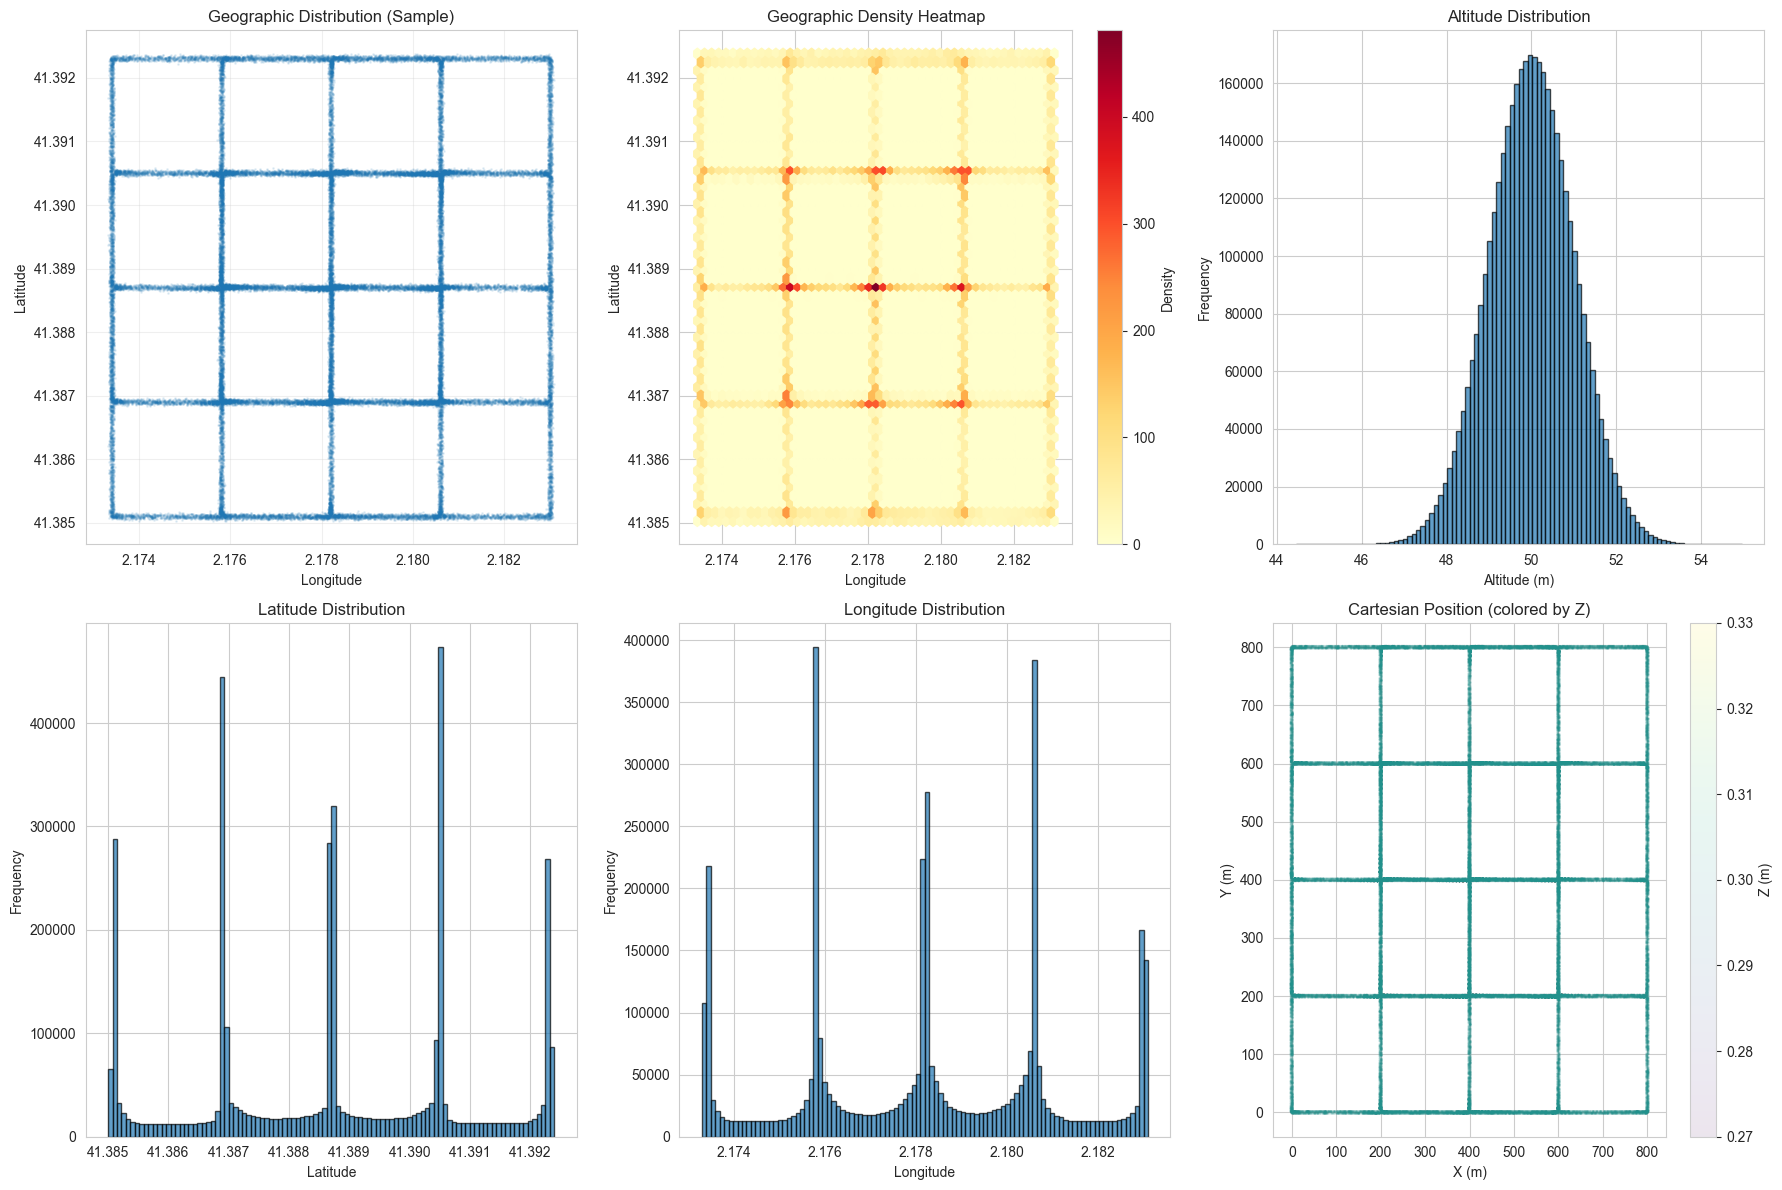


Spatial Statistics:
Latitude range: 41.385006 to 41.392397
Longitude range: 2.173292 to 2.183102
Altitude range: 44.44m to 54.96m
X range: -1.60m to 801.60m
Y range: -1.60m to 801.60m
Z range: 0.30m to 0.30m


In [10]:
sample_size = min(50000, len(df))
df_sample = df.sample(n=sample_size, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

axes[0, 0].scatter(df_sample['longitude'], df_sample['latitude'], alpha=0.1, s=1)
axes[0, 0].set_xlabel('Longitude')
axes[0, 0].set_ylabel('Latitude')
axes[0, 0].set_title('Geographic Distribution (Sample)')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].hexbin(df_sample['longitude'], df_sample['latitude'], gridsize=50, cmap='YlOrRd')
axes[0, 1].set_xlabel('Longitude')
axes[0, 1].set_ylabel('Latitude')
axes[0, 1].set_title('Geographic Density Heatmap')
plt.colorbar(axes[0, 1].collections[0], ax=axes[0, 1], label='Density')

axes[0, 2].hist(df['altitude'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 2].set_xlabel('Altitude (m)')
axes[0, 2].set_ylabel('Frequency')
axes[0, 2].set_title('Altitude Distribution')

axes[1, 0].hist(df['latitude'], bins=100, edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Latitude')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Latitude Distribution')

axes[1, 1].hist(df['longitude'], bins=100, edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Longitude')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Longitude Distribution')

axes[1, 2].scatter(df_sample['x'], df_sample['y'], alpha=0.1, s=1, c=df_sample['z'], cmap='viridis')
axes[1, 2].set_xlabel('X (m)')
axes[1, 2].set_ylabel('Y (m)')
axes[1, 2].set_title('Cartesian Position (colored by Z)')
plt.colorbar(axes[1, 2].collections[0], ax=axes[1, 2], label='Z (m)')

plt.tight_layout()
plt.show()

print("\nSpatial Statistics:")
print(f"Latitude range: {df['latitude'].min():.6f} to {df['latitude'].max():.6f}")
print(f"Longitude range: {df['longitude'].min():.6f} to {df['longitude'].max():.6f}")
print(f"Altitude range: {df['altitude'].min():.2f}m to {df['altitude'].max():.2f}m")
print(f"X range: {df['x'].min():.2f}m to {df['x'].max():.2f}m")
print(f"Y range: {df['y'].min():.2f}m to {df['y'].max():.2f}m")
print(f"Z range: {df['z'].min():.2f}m to {df['z'].max():.2f}m")

## 6. Orientation Analysis (Roll, Pitch, Yaw)

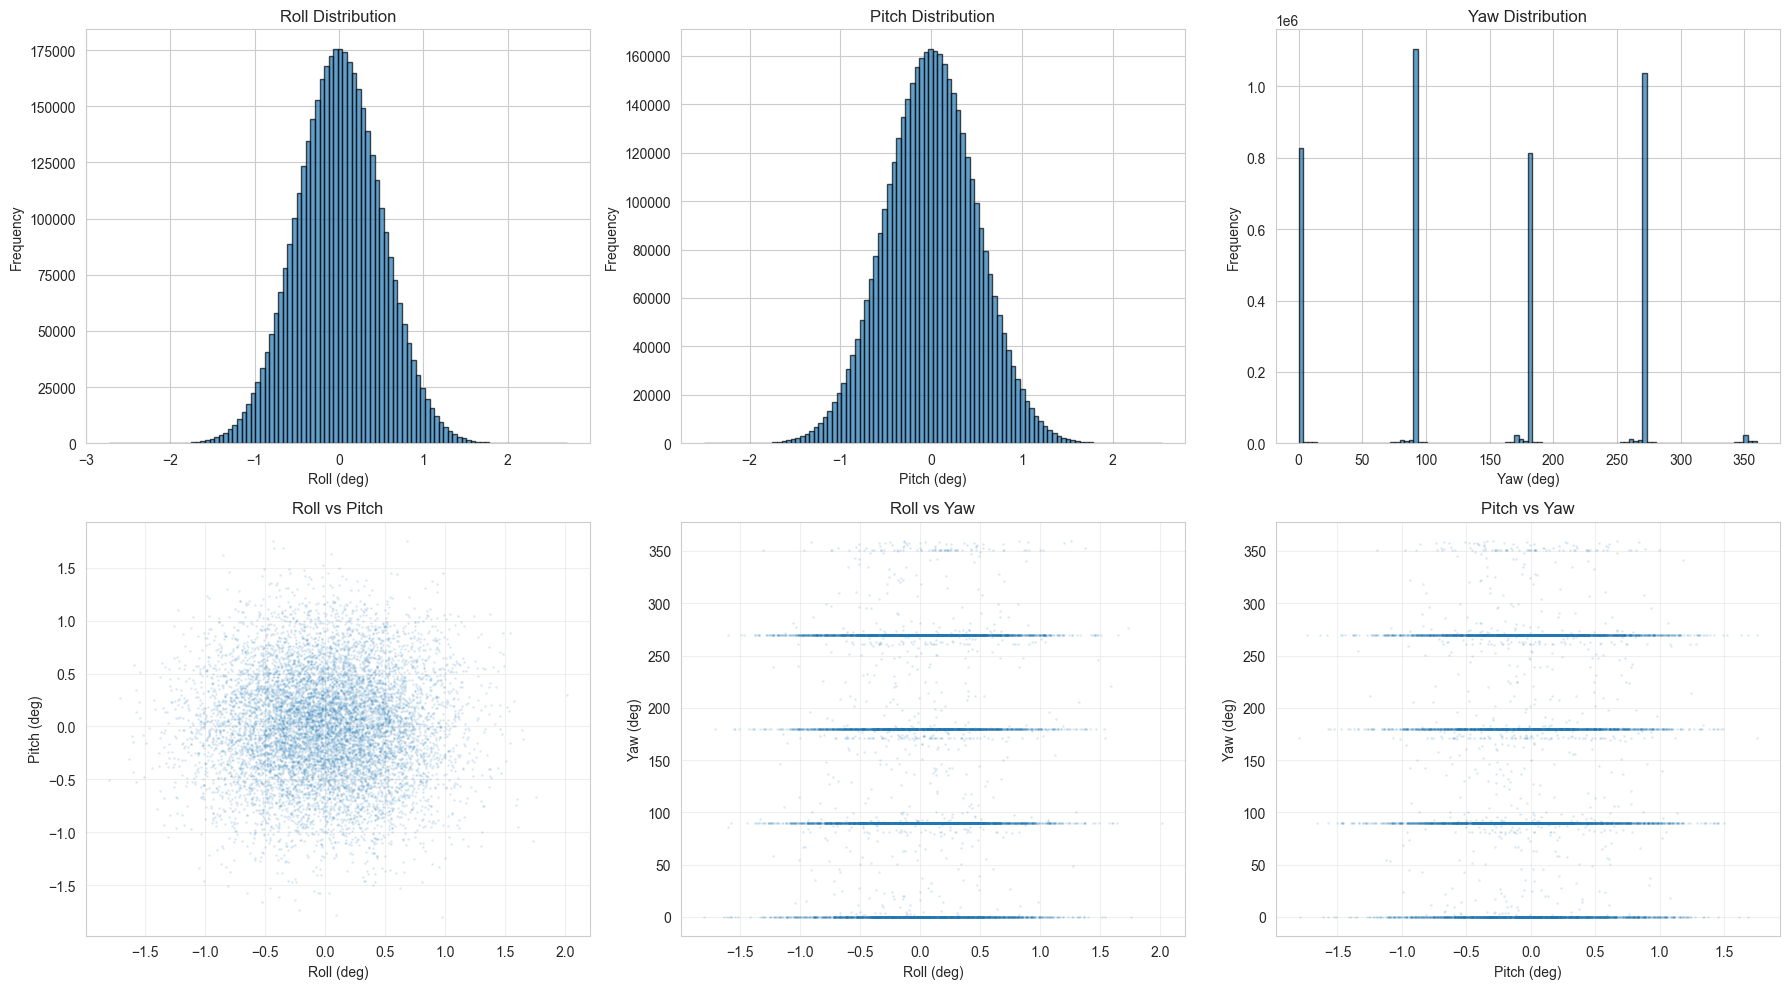


Orientation Statistics:
Roll - Mean: 0.00°, Std: 0.50°
Pitch - Mean: 0.00°, Std: 0.50°
Yaw - Mean: 143.04°, Std: 101.37°


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].hist(df['roll'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Roll (deg)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Roll Distribution')

axes[0, 1].hist(df['pitch'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Pitch (deg)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Pitch Distribution')

axes[0, 2].hist(df['yaw'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 2].set_xlabel('Yaw (deg)')
axes[0, 2].set_ylabel('Frequency')
axes[0, 2].set_title('Yaw Distribution')

sample_idx = np.random.choice(len(df), min(10000, len(df)), replace=False)
sample_data = df.iloc[sample_idx]

axes[1, 0].scatter(sample_data['roll'], sample_data['pitch'], alpha=0.1, s=1)
axes[1, 0].set_xlabel('Roll (deg)')
axes[1, 0].set_ylabel('Pitch (deg)')
axes[1, 0].set_title('Roll vs Pitch')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].scatter(sample_data['roll'], sample_data['yaw'], alpha=0.1, s=1)
axes[1, 1].set_xlabel('Roll (deg)')
axes[1, 1].set_ylabel('Yaw (deg)')
axes[1, 1].set_title('Roll vs Yaw')
axes[1, 1].grid(True, alpha=0.3)

axes[1, 2].scatter(sample_data['pitch'], sample_data['yaw'], alpha=0.1, s=1)
axes[1, 2].set_xlabel('Pitch (deg)')
axes[1, 2].set_ylabel('Yaw (deg)')
axes[1, 2].set_title('Pitch vs Yaw')
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nOrientation Statistics:")
print(f"Roll - Mean: {df['roll'].mean():.2f}°, Std: {df['roll'].std():.2f}°")
print(f"Pitch - Mean: {df['pitch'].mean():.2f}°, Std: {df['pitch'].std():.2f}°")
print(f"Yaw - Mean: {df['yaw'].mean():.2f}°, Std: {df['yaw'].std():.2f}°")

## 7. Velocity and Speed Analysis

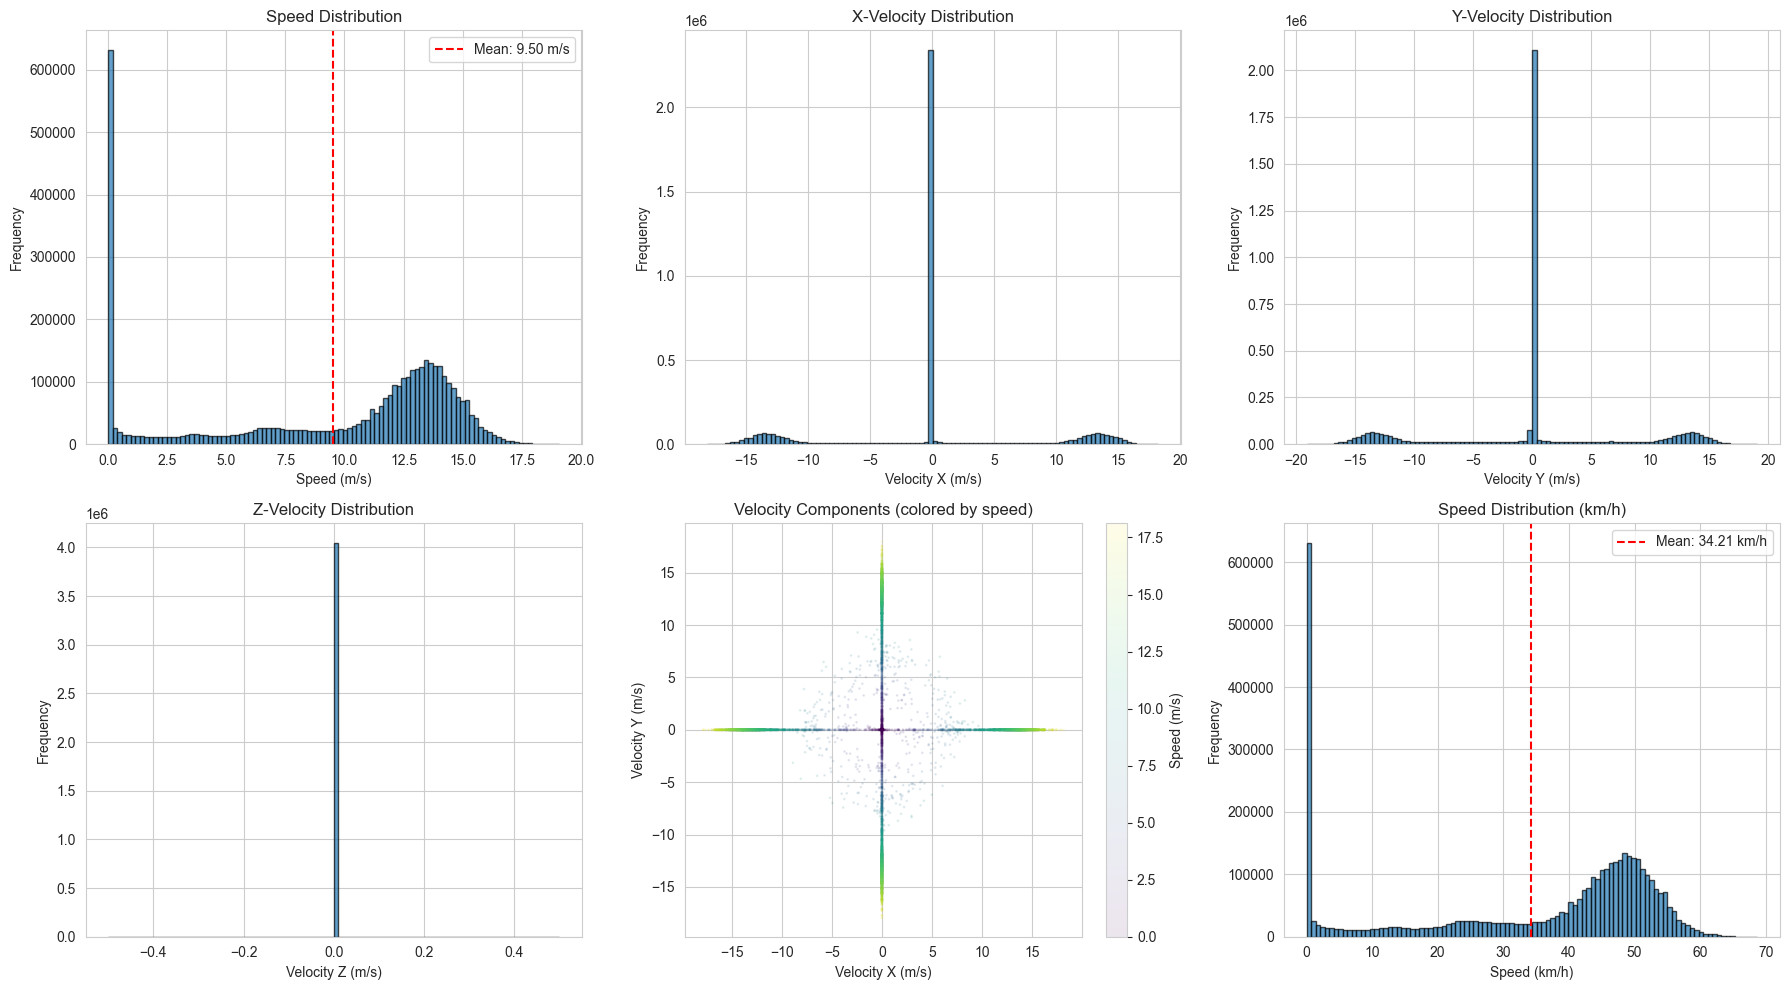


Velocity Statistics:
Speed - Mean: 9.50 m/s (34.21 km/h)
Speed - Std: 5.43 m/s
Speed - Max: 19.09 m/s (68.73 km/h)

Velocity X - Mean: 0.06, Std: 7.81
Velocity Y - Mean: 0.02, Std: 7.66
Velocity Z - Mean: 0.00, Std: 0.00


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].hist(df['speed'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Speed (m/s)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Speed Distribution')
axes[0, 0].axvline(df['speed'].mean(), color='red', linestyle='--', label=f'Mean: {df["speed"].mean():.2f} m/s')
axes[0, 0].legend()

axes[0, 1].hist(df['velocity_x'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Velocity X (m/s)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('X-Velocity Distribution')

axes[0, 2].hist(df['velocity_y'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 2].set_xlabel('Velocity Y (m/s)')
axes[0, 2].set_ylabel('Frequency')
axes[0, 2].set_title('Y-Velocity Distribution')

axes[1, 0].hist(df['velocity_z'], bins=100, edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Velocity Z (m/s)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Z-Velocity Distribution')

sample_idx = np.random.choice(len(df), min(10000, len(df)), replace=False)
sample_data = df.iloc[sample_idx]

axes[1, 1].scatter(sample_data['velocity_x'], sample_data['velocity_y'], 
                   alpha=0.1, s=1, c=sample_data['speed'], cmap='viridis')
axes[1, 1].set_xlabel('Velocity X (m/s)')
axes[1, 1].set_ylabel('Velocity Y (m/s)')
axes[1, 1].set_title('Velocity Components (colored by speed)')
plt.colorbar(axes[1, 1].collections[0], ax=axes[1, 1], label='Speed (m/s)')

speed_kmh = df['speed'] * 3.6
axes[1, 2].hist(speed_kmh, bins=100, edgecolor='black', alpha=0.7)
axes[1, 2].set_xlabel('Speed (km/h)')
axes[1, 2].set_ylabel('Frequency')
axes[1, 2].set_title('Speed Distribution (km/h)')
axes[1, 2].axvline(speed_kmh.mean(), color='red', linestyle='--', label=f'Mean: {speed_kmh.mean():.2f} km/h')
axes[1, 2].legend()

plt.tight_layout()
plt.show()

print("\nVelocity Statistics:")
print(f"Speed - Mean: {df['speed'].mean():.2f} m/s ({df['speed'].mean() * 3.6:.2f} km/h)")
print(f"Speed - Std: {df['speed'].std():.2f} m/s")
print(f"Speed - Max: {df['speed'].max():.2f} m/s ({df['speed'].max() * 3.6:.2f} km/h)")
print(f"\nVelocity X - Mean: {df['velocity_x'].mean():.2f}, Std: {df['velocity_x'].std():.2f}")
print(f"Velocity Y - Mean: {df['velocity_y'].mean():.2f}, Std: {df['velocity_y'].std():.2f}")
print(f"Velocity Z - Mean: {df['velocity_z'].mean():.2f}, Std: {df['velocity_z'].std():.2f}")

## 8. IMU Sensor Analysis (Accelerometer & Gyroscope)

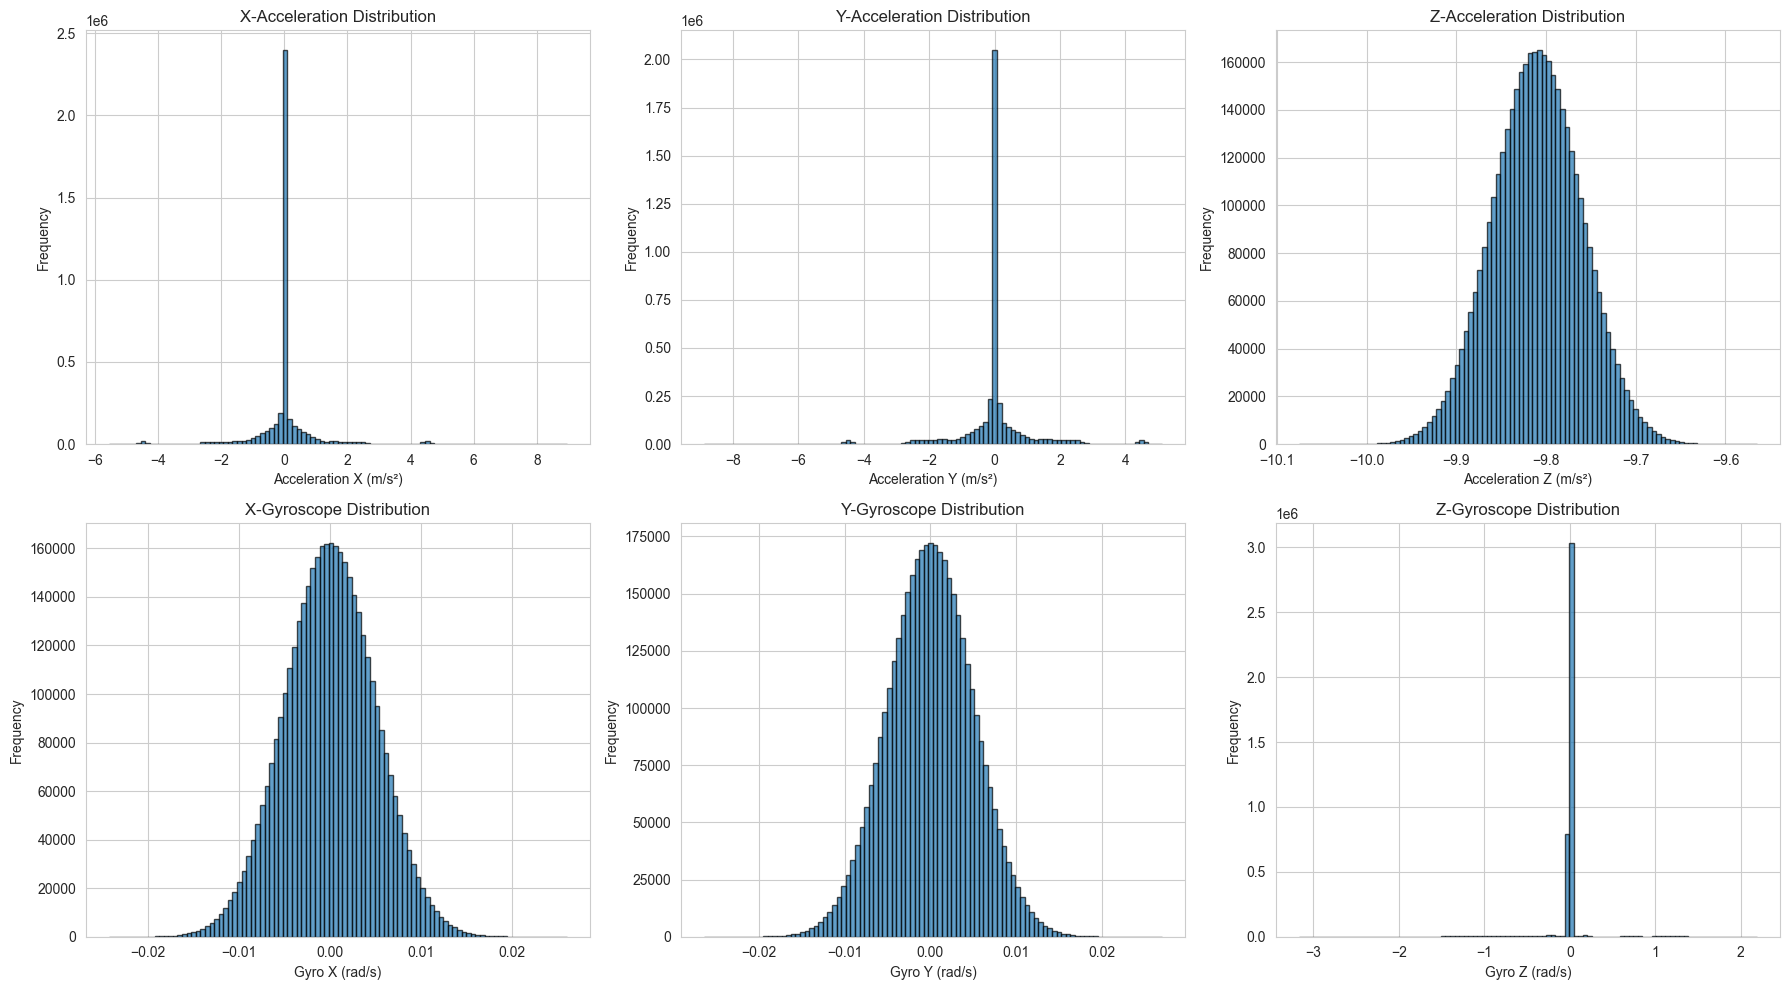


IMU Sensor Statistics:

Accelerometer:
  X - Mean: 0.0011, Std: 0.8949
  Y - Mean: 0.0004, Std: 1.0829
  Z - Mean: -9.8100, Std: 0.0500

Gyroscope:
  X - Mean: 0.000001, Std: 0.005000
  Y - Mean: 0.000001, Std: 0.005000
  Z - Mean: -0.011798, Std: 0.227485


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].hist(df['accel_x'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Acceleration X (m/s²)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('X-Acceleration Distribution')

axes[0, 1].hist(df['accel_y'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Acceleration Y (m/s²)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Y-Acceleration Distribution')

axes[0, 2].hist(df['accel_z'], bins=100, edgecolor='black', alpha=0.7)
axes[0, 2].set_xlabel('Acceleration Z (m/s²)')
axes[0, 2].set_ylabel('Frequency')
axes[0, 2].set_title('Z-Acceleration Distribution')

axes[1, 0].hist(df['gyro_x'], bins=100, edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Gyro X (rad/s)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('X-Gyroscope Distribution')

axes[1, 1].hist(df['gyro_y'], bins=100, edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Gyro Y (rad/s)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Y-Gyroscope Distribution')

axes[1, 2].hist(df['gyro_z'], bins=100, edgecolor='black', alpha=0.7)
axes[1, 2].set_xlabel('Gyro Z (rad/s)')
axes[1, 2].set_ylabel('Frequency')
axes[1, 2].set_title('Z-Gyroscope Distribution')

plt.tight_layout()
plt.show()

print("\nIMU Sensor Statistics:")
print("\nAccelerometer:")
print(f"  X - Mean: {df['accel_x'].mean():.4f}, Std: {df['accel_x'].std():.4f}")
print(f"  Y - Mean: {df['accel_y'].mean():.4f}, Std: {df['accel_y'].std():.4f}")
print(f"  Z - Mean: {df['accel_z'].mean():.4f}, Std: {df['accel_z'].std():.4f}")
print("\nGyroscope:")
print(f"  X - Mean: {df['gyro_x'].mean():.6f}, Std: {df['gyro_x'].std():.6f}")
print(f"  Y - Mean: {df['gyro_y'].mean():.6f}, Std: {df['gyro_y'].std():.6f}")
print(f"  Z - Mean: {df['gyro_z'].mean():.6f}, Std: {df['gyro_z'].std():.6f}")

## 9. Compass Analysis

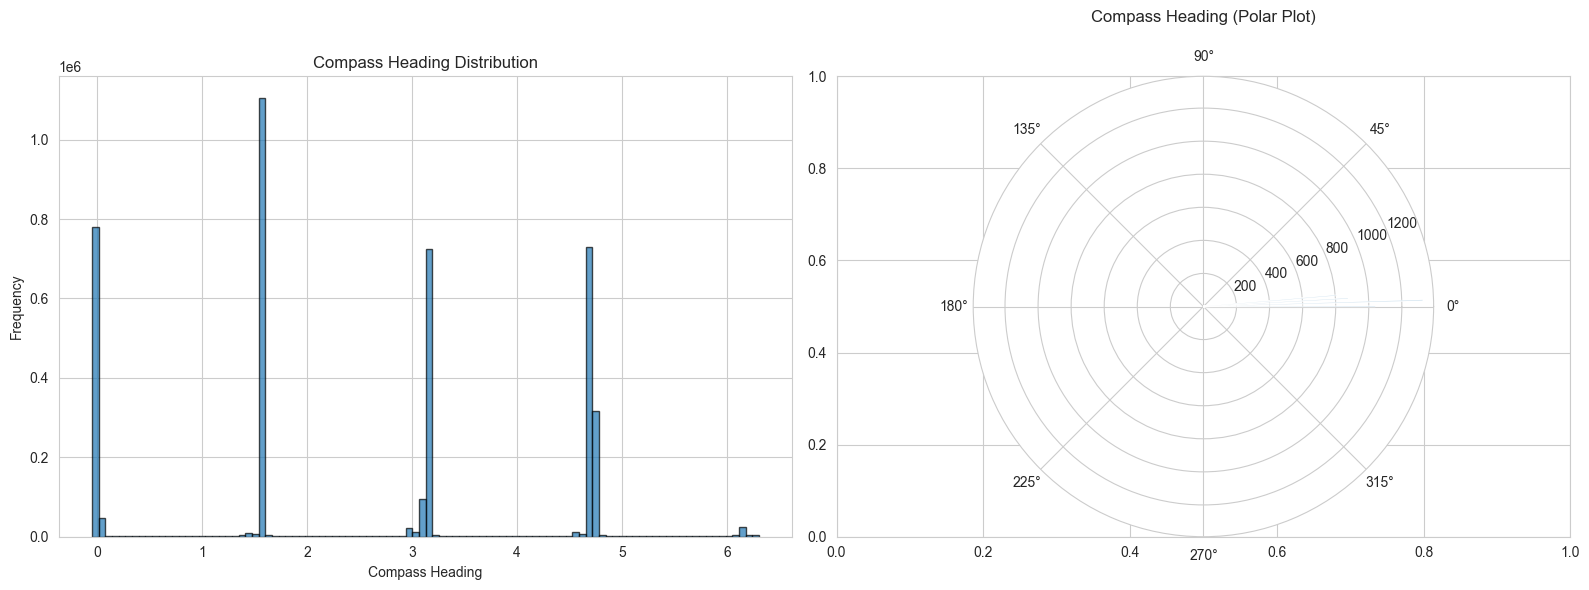


Compass Statistics:
Mean: 2.50
Std: 1.77
Range: -0.05 to 6.31


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].hist(df['compass'], bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Compass Heading')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Compass Heading Distribution')

theta = np.deg2rad(df['compass'].sample(min(5000, len(df)), random_state=42))
axes[1] = plt.subplot(1, 2, 2, projection='polar')
axes[1].hist(theta, bins=36, alpha=0.7)
axes[1].set_title('Compass Heading (Polar Plot)', pad=20)

plt.tight_layout()
plt.show()

print("\nCompass Statistics:")
print(f"Mean: {df['compass'].mean():.2f}")
print(f"Std: {df['compass'].std():.2f}")
print(f"Range: {df['compass'].min():.2f} to {df['compass'].max():.2f}")

## 10. Correlation Analysis

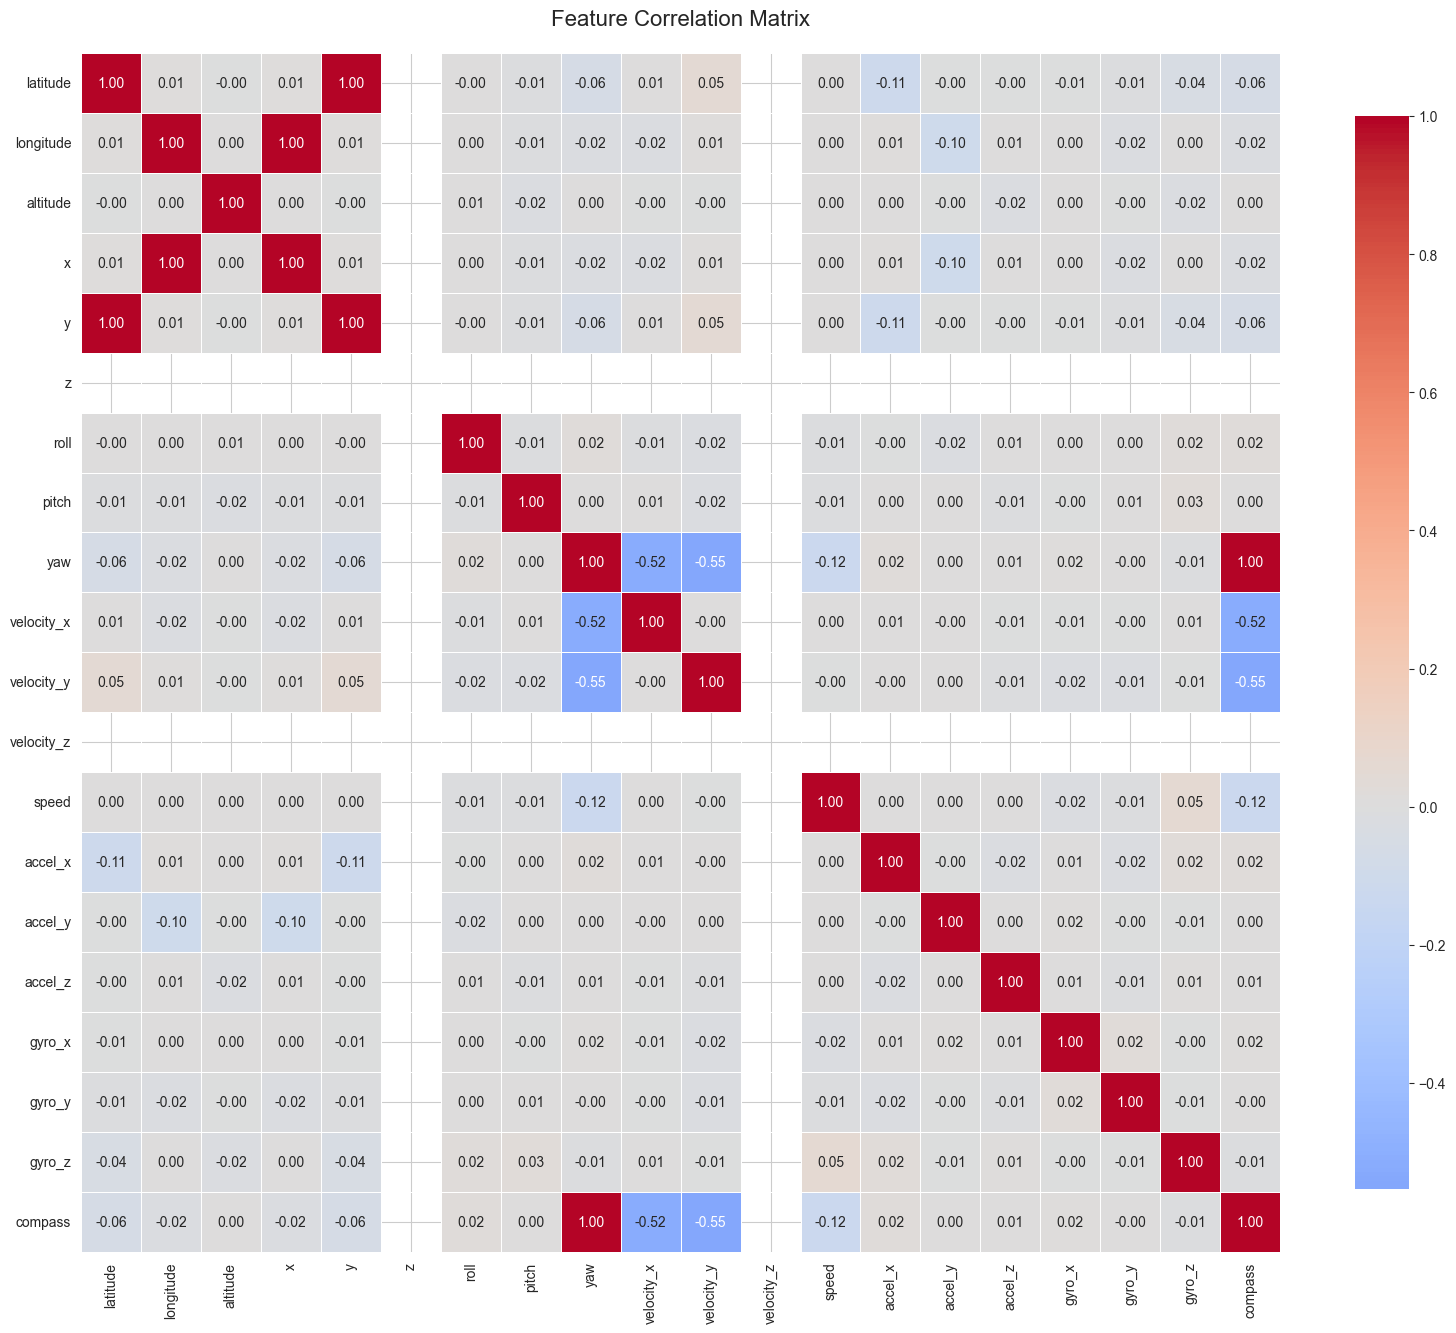


Top 10 Positive Correlations (excluding diagonal):
compass     yaw           0.999985
yaw         compass       0.999985
longitude   x             0.999979
x           longitude     0.999979
y           latitude      0.999966
latitude    y             0.999966
gyro_z      speed         0.054916
speed       gyro_z        0.054916
velocity_y  latitude      0.052764
latitude    velocity_y    0.052764
dtype: float64

Top 10 Negative Correlations:
yaw         velocity_y   -0.553296
velocity_y  yaw          -0.553296
            compass      -0.553250
compass     velocity_y   -0.553250
            velocity_x   -0.518298
velocity_x  compass      -0.518298
yaw         velocity_x   -0.518273
velocity_x  yaw          -0.518273
speed       compass      -0.124416
compass     speed        -0.124416
dtype: float64


In [15]:
numeric_cols = ['latitude', 'longitude', 'altitude', 'x', 'y', 'z', 
                'roll', 'pitch', 'yaw', 'velocity_x', 'velocity_y', 'velocity_z', 'speed',
                'accel_x', 'accel_y', 'accel_z', 'gyro_x', 'gyro_y', 'gyro_z', 'compass']

sample_for_corr = df[numeric_cols].sample(min(10000, len(df)), random_state=42)
corr_matrix = sample_for_corr.corr()

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Feature Correlation Matrix', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

print("\nTop 10 Positive Correlations (excluding diagonal):")
corr_pairs = corr_matrix.unstack()
corr_pairs = corr_pairs[corr_pairs < 1.0]
print(corr_pairs.sort_values(ascending=False).head(10))

print("\nTop 10 Negative Correlations:")
print(corr_pairs.sort_values().head(10))

## 11. Statistical Tests for Normality

In [16]:
test_cols = ['speed', 'accel_x', 'accel_y', 'accel_z', 'gyro_x', 'gyro_y', 'gyro_z']
sample_for_test = df[test_cols].sample(min(5000, len(df)), random_state=42)

print("Shapiro-Wilk Normality Test Results:")
print("(p-value < 0.05 indicates non-normal distribution)\n")

for col in test_cols:
    stat, p_value = stats.shapiro(sample_for_test[col])
    print(f"{col:12s}: statistic={stat:.6f}, p-value={p_value:.6e} {'(Normal)' if p_value > 0.05 else '(Non-normal)'}")

Shapiro-Wilk Normality Test Results:
(p-value < 0.05 indicates non-normal distribution)

speed       : statistic=0.839600, p-value=1.711557e-57 (Non-normal)
accel_x     : statistic=0.670588, p-value=2.190232e-71 (Non-normal)
accel_y     : statistic=0.759169, p-value=3.774494e-65 (Non-normal)
accel_z     : statistic=0.999516, p-value=2.383131e-01 (Normal)
gyro_x      : statistic=0.999823, p-value=9.728972e-01 (Normal)
gyro_y      : statistic=0.999545, p-value=2.919069e-01 (Normal)
gyro_z      : statistic=0.264132, p-value=9.979743e-89 (Non-normal)


## 12. Outlier Detection

Outlier Analysis (IQR Method):

speed       :        0 outliers ( 0.00%)
accel_x     :  1917280 outliers (47.35%)
accel_y     :  1462662 outliers (36.13%)
accel_z     :    28430 outliers ( 0.70%)
gyro_x      :    28570 outliers ( 0.71%)
gyro_y      :    28193 outliers ( 0.70%)
gyro_z      :   237851 outliers ( 5.87%)


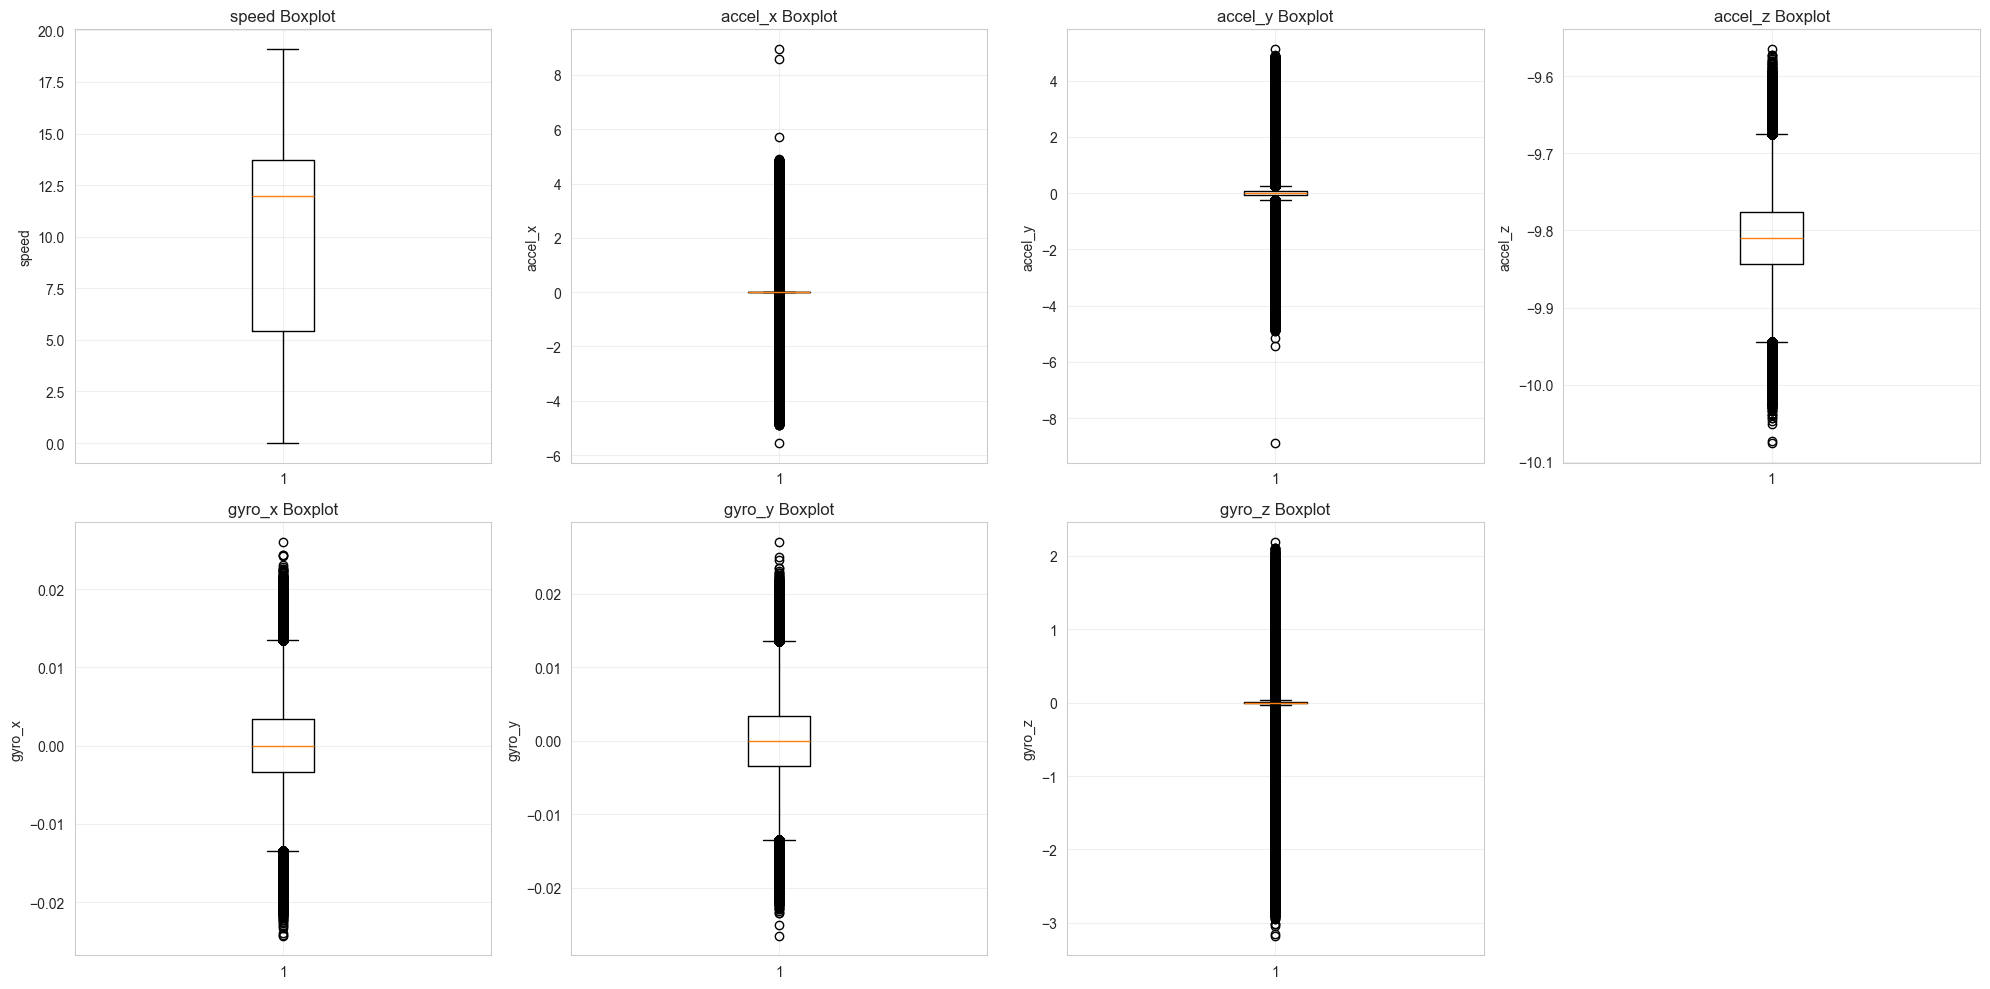

In [17]:
def detect_outliers_iqr(data: pd.Series) -> tuple[int, float]:
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((data < lower_bound) | (data > upper_bound)).sum()
    return outliers, (outliers / len(data)) * 100

print("Outlier Analysis (IQR Method):\n")
outlier_cols = ['speed', 'accel_x', 'accel_y', 'accel_z', 'gyro_x', 'gyro_y', 'gyro_z']

for col in outlier_cols:
    count, pct = detect_outliers_iqr(df[col])
    print(f"{col:12s}: {count:8d} outliers ({pct:5.2f}%)")

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for idx, col in enumerate(outlier_cols):
    axes[idx].boxplot(df[col].values)
    axes[idx].set_ylabel(col)
    axes[idx].set_title(f'{col} Boxplot')
    axes[idx].grid(True, alpha=0.3)

axes[-1].axis('off')
plt.tight_layout()
plt.show()

## 13. Sample Vehicle Trajectory Analysis

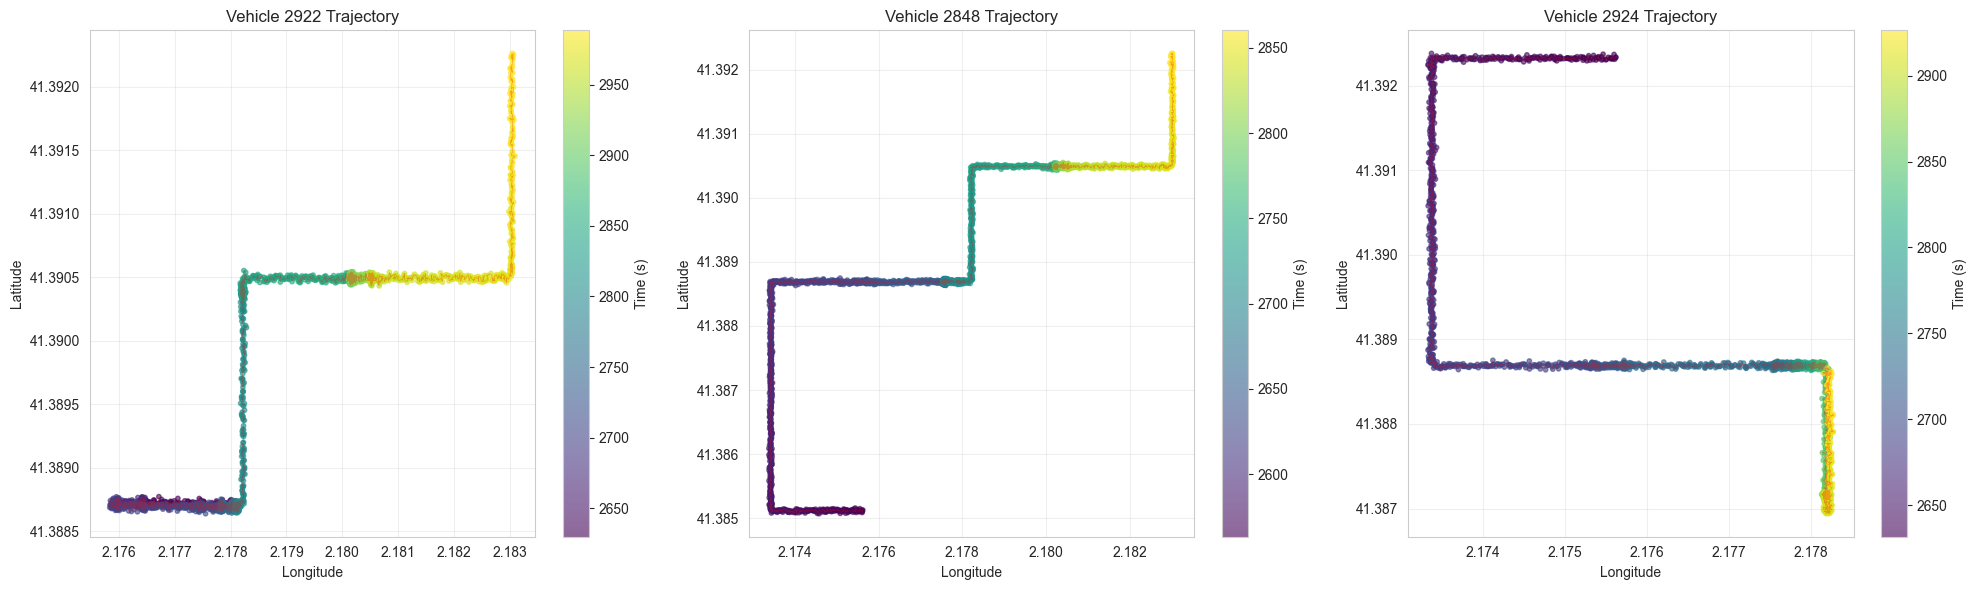


Vehicle 2922:
  Records: 3585
  Duration: 358.40s
  Avg Speed: 3.26 m/s (11.74 km/h)
  Max Speed: 14.31 m/s (51.52 km/h)

Vehicle 2848:
  Records: 2971
  Duration: 297.00s
  Avg Speed: 5.95 m/s (21.44 km/h)
  Max Speed: 13.17 m/s (47.43 km/h)

Vehicle 2924:
  Records: 2947
  Duration: 294.60s
  Avg Speed: 4.64 m/s (16.69 km/h)
  Max Speed: 11.80 m/s (42.49 km/h)


In [18]:
sample_vehicles = df['vehicle_id'].value_counts().head(3).index

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, vehicle_id in enumerate(sample_vehicles):
    vehicle_data = df[df['vehicle_id'] == vehicle_id].sort_values('timestamp')
    
    scatter = axes[idx].scatter(vehicle_data['longitude'], vehicle_data['latitude'],
                                c=vehicle_data['timestamp'], s=10, cmap='viridis', alpha=0.6)
    axes[idx].plot(vehicle_data['longitude'], vehicle_data['latitude'], 
                   'r-', alpha=0.3, linewidth=0.5)
    axes[idx].set_xlabel('Longitude')
    axes[idx].set_ylabel('Latitude')
    axes[idx].set_title(f'Vehicle {vehicle_id} Trajectory')
    axes[idx].grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=axes[idx], label='Time (s)')

plt.tight_layout()
plt.show()

for vehicle_id in sample_vehicles:
    vehicle_data = df[df['vehicle_id'] == vehicle_id]
    print(f"\nVehicle {vehicle_id}:")
    print(f"  Records: {len(vehicle_data)}")
    print(f"  Duration: {vehicle_data['timestamp'].max() - vehicle_data['timestamp'].min():.2f}s")
    print(f"  Avg Speed: {vehicle_data['speed'].mean():.2f} m/s ({vehicle_data['speed'].mean() * 3.6:.2f} km/h)")
    print(f"  Max Speed: {vehicle_data['speed'].max():.2f} m/s ({vehicle_data['speed'].max() * 3.6:.2f} km/h)")

## 14. Key Findings Summary

In [19]:
print("="*80)
print("KEY FINDINGS SUMMARY")
print("="*80)

print("\n1. DATASET OVERVIEW:")
print(f"   - Total records: {len(df):,}")
print(f"   - Unique vehicles: {df['vehicle_id'].nunique()}")
print(f"   - Duration: {df['timestamp'].max() - df['timestamp'].min():.1f} seconds")
print(f"   - Sampling rate: {metadata['sampling_rate_hz']} Hz")

print("\n2. DATA QUALITY:")
print(f"   - Missing values: {df.isnull().sum().sum()}")
print(f"   - Duplicate rows: {df.duplicated().sum()}")
print(f"   - Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\n3. VEHICLE BEHAVIOR:")
print(f"   - Avg records per vehicle: {vehicle_counts.mean():.0f}")
print(f"   - Avg speed: {df['speed'].mean():.2f} m/s ({df['speed'].mean() * 3.6:.2f} km/h)")
print(f"   - Max speed observed: {df['speed'].max():.2f} m/s ({df['speed'].max() * 3.6:.2f} km/h)")

print("\n4. SPATIAL COVERAGE:")
print(f"   - Latitude range: {df['latitude'].max() - df['latitude'].min():.6f}°")
print(f"   - Longitude range: {df['longitude'].max() - df['longitude'].min():.6f}°")
print(f"   - Altitude range: {df['altitude'].min():.1f}m to {df['altitude'].max():.1f}m")

print("\n5. SENSOR CHARACTERISTICS:")
print(f"   - GPS noise std (config): {metadata['gps_noise_std_meters']} m")
print(f"   - IMU accel noise std (config): {metadata['imu_accel_noise_std']} m/s²")
print(f"   - IMU gyro noise std (config): {metadata['imu_gyro_noise_std']} rad/s")

print("\n6. RECOMMENDATIONS FOR ANOMALY DETECTION:")
print(f"   - Consider speed outliers (>{df['speed'].quantile(0.99):.2f} m/s) as potential anomalies")
print("   - Monitor sudden changes in acceleration and gyroscope readings")
print("   - Track vehicles with unusual trajectory patterns")
print("   - Use temporal patterns for baseline behavior modeling")

print("\n" + "="*80)

KEY FINDINGS SUMMARY

1. DATASET OVERVIEW:
   - Total records: 4,048,814
   - Unique vehicles: 3999
   - Duration: 3599.8 seconds
   - Sampling rate: 10 Hz

2. DATA QUALITY:
   - Missing values: 0
   - Duplicate rows: 0
   - Memory usage: 710.47 MB

3. VEHICLE BEHAVIOR:
   - Avg records per vehicle: 1012
   - Avg speed: 9.50 m/s (34.21 km/h)
   - Max speed observed: 19.09 m/s (68.73 km/h)

4. SPATIAL COVERAGE:
   - Latitude range: 0.007391°
   - Longitude range: 0.009810°
   - Altitude range: 44.4m to 55.0m

5. SENSOR CHARACTERISTICS:
   - GPS noise std (config): 2.0 m
   - IMU accel noise std (config): 0.1 m/s²
   - IMU gyro noise std (config): 0.01 rad/s

6. RECOMMENDATIONS FOR ANOMALY DETECTION:
   - Consider speed outliers (>16.38 m/s) as potential anomalies
   - Monitor sudden changes in acceleration and gyroscope readings
   - Track vehicles with unusual trajectory patterns
   - Use temporal patterns for baseline behavior modeling

